# ML Lab 1 – Exploring the Ames Housing dataset

In this notebook we take a first look at the Ames Housing data with pandas: what's in it, what's missing, what looks weird, and which features seem to be connected. We check the data quality (missing values, outliers), look at distributions and relationships with different kinds of plots, and think about which features we'd drop, which new ones we could build, and what outside data could help.

## What this notebook does

We want to understand the Ames Housing data (2930 houses, 82 features) before we use it in the next labs. The notebook goes through these steps:

1. **Load the data:** read the CSV with pandas and check that it looks right.
2. **Look at the features:** which columns are numbers, which are categories, and which ones are tricky.
3. **Clean the data (preprocessing):** deal with missing values and outliers, decide which columns we'd drop, and think of new ones we could create. We also write down what outside data could help.
4. **Plots:** at least 10 different plots (histogram, scatter, box, violin, heatmap, ...) to see how values are spread and how features are connected, with a short explanation under each.
5. **Bonus, linear regression:** pick two pairs of features that look linearly related, fit a line, and compare real vs. predicted values.

Each part has a short text explaining what we did and what we found.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Loading the data

`AmesHousing.csv` is **tab-separated**, not comma-separated, so we need `sep="\t"`. Without it pandas reads each row as one giant column (we got `shape = (2930, 1)` at first, which was the hint that something was off).

Result: **2930 rows (houses)** and **82 columns (features)**.

In [2]:
housing = pd.read_csv("AmesHousing.csv", sep="\t")
print(housing.shape)
housing.head()

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

Quick takeaways from `info()`:
- 82 columns: 28 `int64`, 11 `float64`, 43 `str`.
- Some columns have fewer than 2930 non-null values (e.g. `Lot Frontage` has 2440, `Alley` only 198), so there's missing data. We look at that in section 3.

In [4]:
num_cols = housing.select_dtypes(include="number").columns.tolist()
cat_cols = housing.select_dtypes(exclude="number").columns.tolist()
print(len(num_cols), "numeric,", len(cat_cols), "categorical")
print(num_cols)

39 numeric, 43 categorical
['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'SalePrice']


## 2. Looking at features

First we split the columns into numeric and categorical. pandas does this by data type, but the data type doesn't always match what a column *means*, so we also checked the description file (`AmesExplanations.txt`), which labels every feature as nominal, ordinal, discrete or continuous.

In [5]:
# by meaning, based on AmesExplanations.txt
identifiers = ["Order", "PID"]

numeric_continuous = ["Lot Frontage", "Lot Area", "Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2",
                      "Bsmt Unf SF", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF", "Low Qual Fin SF",
                      "Gr Liv Area", "Garage Area", "Wood Deck SF", "Open Porch SF", "Enclosed Porch",
                      "3Ssn Porch", "Screen Porch", "Pool Area", "Misc Val", "SalePrice"]

numeric_discrete = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Mo Sold", "Yr Sold",
                    "Bsmt Full Bath", "Bsmt Half Bath", "Full Bath", "Half Bath", "Bedroom AbvGr",
                    "Kitchen AbvGr", "TotRms AbvGrd", "Fireplaces", "Garage Cars"]

categorical_nominal = ["MS SubClass", "MS Zoning", "Street", "Alley", "Land Contour", "Lot Config",
                       "Neighborhood", "Condition 1", "Condition 2", "Bldg Type", "House Style",
                       "Roof Style", "Roof Matl", "Exterior 1st", "Exterior 2nd", "Mas Vnr Type",
                       "Foundation", "Heating", "Central Air", "Garage Type", "Misc Feature",
                       "Sale Type", "Sale Condition"]

categorical_ordinal = ["Overall Qual", "Overall Cond", "Lot Shape", "Utilities", "Land Slope",
                       "Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
                       "BsmtFin Type 1", "BsmtFin Type 2", "Heating QC", "Electrical", "Kitchen Qual",
                       "Functional", "Fireplace Qu", "Garage Finish", "Garage Qual", "Garage Cond",
                       "Paved Drive", "Pool QC", "Fence"]

groups = {"identifiers": identifiers, "numeric continuous": numeric_continuous,
          "numeric discrete": numeric_discrete, "categorical nominal": categorical_nominal,
          "categorical ordinal": categorical_ordinal}

all_listed = sum(groups.values(), [])
print("listed:", len(all_listed), "| unique:", len(set(all_listed)), "| in data:", housing.shape[1])
print("missing from lists:", set(housing.columns) - set(all_listed))
print("not in data:", set(all_listed) - set(housing.columns))
for name, cols in groups.items():
    print(f"{name}: {len(cols)}")

listed: 82 | unique: 82 | in data: 82
missing from lists: set()
not in data: set()
identifiers: 2
numeric continuous: 20
numeric discrete: 14
categorical nominal: 23
categorical ordinal: 23


**Result:** pandas finds 39 numeric and 43 categorical columns. By meaning it looks a bit different:
- **Identifiers (2):** `Order` and `PID` are just IDs, even though they are numbers.
- **Numeric, continuous (20):** sizes and areas in square feet, `Lot Frontage`, `Misc Val` and `SalePrice`.
- **Numeric, discrete (14):** counts (bathrooms, bedrooms, fireplaces, garage cars) and years/months.
- **Categorical, nominal (23):** no order, e.g. `Neighborhood`, `House Style`, `Foundation`. This includes `MS SubClass`, which is stored as a number but is really a code for the dwelling type.
- **Categorical, ordinal (23):** have a natural order, e.g. the quality ratings (Ex > Gd > TA > Fa > Po). Two of them, `Overall Qual` and `Overall Cond` (1–10), are stored as numbers.

So 5 columns are numbers by data type but not really numeric in meaning (`Order`, `PID`, `MS SubClass`, `Overall Qual`, `Overall Cond`).

In [6]:
corr = housing[num_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
upper.stack().sort_values(ascending=False).head(7)

Order          Yr Sold          0.975993
Garage Cars    Garage Area      0.889676
Year Built     Garage Yr Blt    0.834849
Gr Liv Area    TotRms AbvGrd    0.807772
Total Bsmt SF  1st Flr SF       0.800720
Overall Qual   SalePrice        0.799262
Gr Liv Area    SalePrice        0.706780
dtype: float64

In [7]:
print("Garage built same year as house:", (housing["Garage Yr Blt"] == housing["Year Built"]).mean().round(2))
print("Never remodeled:", (housing["Year Remod/Add"] == housing["Year Built"]).mean().round(2))

Garage built same year as house: 0.76
Never remodeled: 0.54


### Connections between features

We checked the correlations between all numeric columns and looked at the strongest pairs:

- **Garage size:** `Garage Cars` and `Garage Area` (r = 0.89) measure the same thing in two ways, number of cars and square feet.
- **Garage and house age:** `Year Built` and `Garage Yr Blt` (r = 0.83). For 76% of the houses the garage was built in the same year as the house.
- **House size and rooms:** `Gr Liv Area` goes with `TotRms AbvGrd` (r = 0.81), and `TotRms AbvGrd` with `Bedroom AbvGr` (r = 0.67). Bigger houses have more rooms. `2nd Flr SF` is part of `Gr Liv Area` (r = 0.66).
- **Basement and first floor:** `Total Bsmt SF` and `1st Flr SF` (r = 0.80). This makes sense, because a basement usually sits under the first floor and has about the same size.
- **Remodeling:** `Year Remod/Add` and `Garage Yr Blt` (r = 0.65). 54% of the houses were never remodeled, since their remodel year equals the build year.
- **Price:** `SalePrice` goes with `Overall Qual` (r = 0.80) and with `Gr Liv Area` (r = 0.71). Better quality and more living space mean a higher price.
- **Order and sale year:** `Order` and `Yr Sold` have r = −0.98. That's odd for a column that is just a row number. It turns out the rows are sorted by sale year from the latest to the earliest, so the row number carries no meaning about the house itself. This is another reason to drop `Order`.


In [8]:
print("Raw value:", housing["Order"].corr(housing["Yr Sold"]))

Raw value: -0.9759929037175541



These are only correlations between numeric columns, and they only measure straight-line relationships. Connections between categorical columns (e.g. `Neighborhood` and `MS Zoning`) are not covered here.

## 3. Preprocessing 

In [9]:
clean_df = housing.copy()   # housing stays raw, clean_df gets cleaned

In [10]:
missing = housing.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(housing) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
Pool QC,2917,99.6
Misc Feature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
Mas Vnr Type,1775,60.6
Fireplace Qu,1422,48.5
Lot Frontage,490,16.7
Garage Qual,159,5.4
Garage Cond,159,5.4
Garage Yr Blt,159,5.4


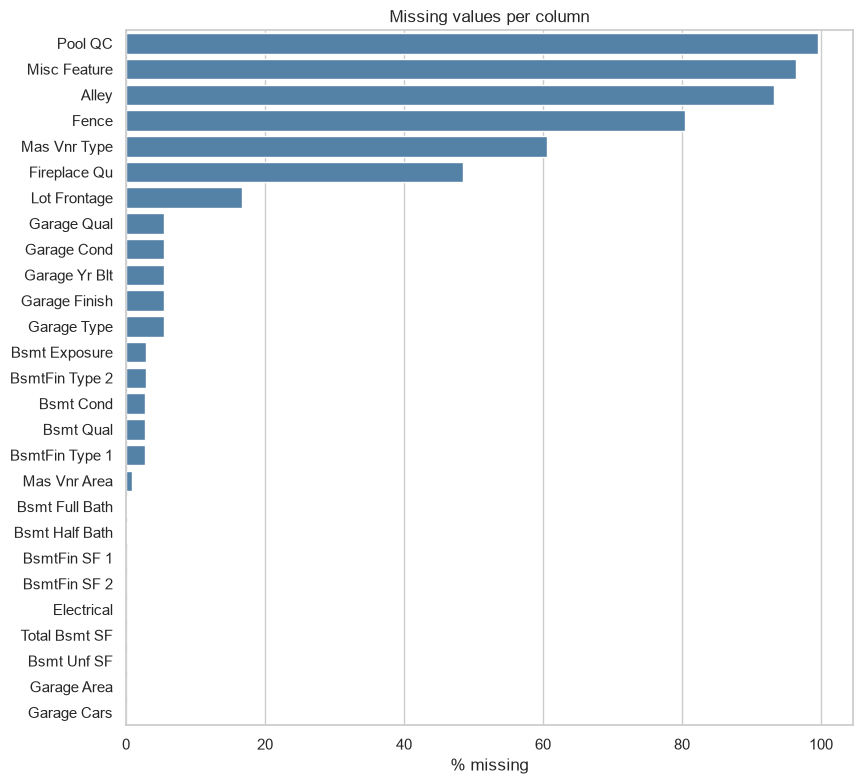

In [11]:
plt.figure(figsize=(9, 8))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.tight_layout()
plt.ylabel("")
plt.show()

### 3.1 Missing values

27 columns have missing values. The biggest are `Pool QC` (99.6%), `Misc Feature` (96.4%), `Alley` (93.2%) and `Fence` (80.5%). The garage columns all miss the same 159 rows, and the basement columns about 80.

But NaN doesn't always mean "data lost". The description file says `NA` means "no pool / no alley / no garage / ...". We tested this: for all 11 columns we checked, 100% of the houses without the feature (e.g. `Pool Area = 0`) have NaN there. So NaN mostly means "this house doesn't have it", and dropping `Pool QC` for being 99.6% empty would throw away information.

`Mas Vnr Type` has 1775 NaN and no "None" category at all. pandas reads the string "None" as NaN, and 1748 houses have `Mas Vnr Area = 0`, so these are houses without veneer. Only 23 rows are really missing.

Real missing data: `Lot Frontage` (490 rows, 16.7%), 23 veneer rows, `Electrical` (1 row), and a few houses (about 10) that have a basement or garage but a missing label.

### 3.2 How we fill them

- **NaN = feature doesn't exist:** text columns get `"None"`, numeric ones (areas, counts) get 0.
- **`Lot Frontage`:** real missing data, filled with the median of the same neighborhood, because lots in one neighborhood are similar.
- **`Electrical`:** one row, filled with the most common value.
- **Simplification:** the ~10 houses with a missing basement or garage label are handled like the rest. That's a very small share of 2930 rows.
- **`Garage Yr Blt`:** stays NaN for houses without a garage. 0 would be a fake year.

In [12]:
none_cat = ["Alley", "Fence", "Misc Feature", "Pool QC", "Fireplace Qu", "Mas Vnr Type",
            "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
            "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
zero_num = ["Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
            "Bsmt Full Bath", "Bsmt Half Bath", "Garage Area", "Garage Cars"]
clean_df[none_cat] = clean_df[none_cat].fillna("None")
clean_df[zero_num] = clean_df[zero_num].fillna(0)

clean_df["Lot Frontage"] = (clean_df.groupby("Neighborhood")["Lot Frontage"]
                            .transform(lambda s: s.fillna(s.median())))
clean_df["Lot Frontage"] = clean_df["Lot Frontage"].fillna(clean_df["Lot Frontage"].median())

clean_df["Electrical"] = clean_df["Electrical"].fillna(clean_df["Electrical"].mode()[0])

bad = clean_df["Garage Yr Blt"] > 2010
clean_df.loc[bad, "Garage Yr Blt"] = clean_df.loc[bad, "Year Built"]

print(clean_df.shape)

(2930, 82)


In [13]:
housing["Garage Yr Blt"].describe()

count    2771.000000
mean     1978.132443
std        25.528411
min      1895.000000
25%      1960.000000
50%      1979.000000
75%      2002.000000
max      2207.000000
Name: Garage Yr Blt, dtype: float64

In [14]:
housing[housing["Garage Yr Blt"] > 2010][["Year Built", "Garage Yr Blt", "Yr Sold"]]

,Year Built,Garage Yr Blt,Yr Sold
2260,2006,2207.0,2007


In [15]:
big = (housing["Gr Liv Area"] > 4000) & (housing["Sale Condition"] == "Partial")
housing.loc[big, ["Gr Liv Area", "SalePrice", "Sale Condition"]]

,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
2180,5095,183850,Partial
2181,4676,184750,Partial


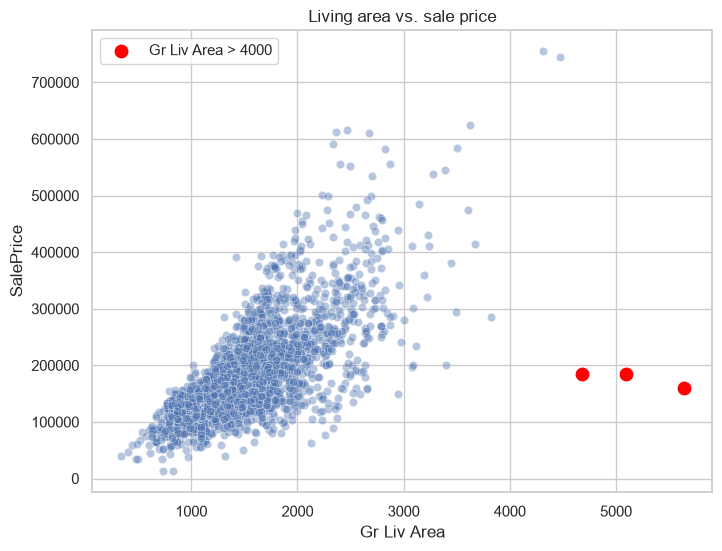

In [16]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=housing, x="Gr Liv Area", y="SalePrice", alpha=0.4)
plt.scatter(housing.loc[big, "Gr Liv Area"], housing.loc[big, "SalePrice"],
            color="red", s=80, label="Gr Liv Area > 4000")
plt.title("Living area vs. sale price")
plt.legend()
plt.show()

### 3.3 Outliers

**Plot:** living area vs. sale price. **Question:** are there houses that don't follow the trend?

Price grows with living area, but 5 houses have more than 4000 sq ft. Three of them (4676, 5095 and 5642 sq ft) sold for only 160k–185k, far below the trend. All three have `Sale Condition = Partial`, which means the house wasn't finished when it was assessed, so the price doesn't reflect the full house. We remove these 3 rows. The other two big houses (4316 and 4476 sq ft, about 750k) follow the trend, so we keep them.

We also found one typo: a house built in 2006 has `Garage Yr Blt = 2207`. We replace it with its `Year Built`.

After this the data has 2927 rows.

In [17]:
bad = clean_df["Garage Yr Blt"] > 2010
clean_df.loc[bad, "Garage Yr Blt"] = clean_df.loc[bad, "Year Built"]

outliers = (clean_df["Gr Liv Area"] > 4000) & (clean_df["Sale Condition"] == "Partial")
clean_df = clean_df[~outliers].copy()
print(clean_df.shape)

(2927, 82)


In [18]:
for col in cat_cols:
    top = housing[col].value_counts(normalize=True, dropna=False)
    if top.iloc[0] > 0.95:
        print(col, top.index[0], round(top.iloc[0], 3))

Street Pave 0.996
Utilities AllPub 0.999
Land Slope Gtl 0.952
Condition 2 Norm 0.99
Roof Matl CompShg 0.985
Heating GasA 0.985
Pool QC nan 0.996
Misc Feature nan 0.964


### 3.4 Features we'd drop

- **`Order`, `PID`:** just IDs. `Order` is only the row number (the rows are sorted by sale year).
- **`Garage Area` or `Garage Cars`:** r = 0.89, they measure the same thing.
- **`Garage Yr Blt`:** r = 0.83 with `Year Built`, and 76% of garages were built the same year as the house.
- **Almost constant columns:** [list from the check above, e.g. `Street` is 99.6% one value]. If nearly every house has the same value, the column can't tell houses apart.
- **`Pool QC`, `Misc Feature`:** more than 96% empty. We keep the information as a yes/no feature instead (below).

### 3.5 New features

| Feature | How | Why |
|---|---|---|
| `Total SF` | above-ground living area + basement | total space says more than single floors |
| `Total Bath` | full baths + 0.5 × half baths, basement included | one number instead of four columns |
| `House Age` | `Yr Sold` − `Year Built` | age is easier to read than a year |
| `Has Pool`, `Has Garage` | area > 0 | yes/no versions of mostly empty columns |

In [19]:
clean_df["Total SF"] = clean_df["Gr Liv Area"] + clean_df["Total Bsmt SF"]
clean_df["Total Bath"] = (clean_df["Full Bath"] + 0.5 * clean_df["Half Bath"]
                          + clean_df["Bsmt Full Bath"] + 0.5 * clean_df["Bsmt Half Bath"])
clean_df["House Age"] = clean_df["Yr Sold"] - clean_df["Year Built"]
clean_df["Has Pool"] = (clean_df["Pool Area"] > 0).astype(int)
clean_df["Has Garage"] = (clean_df["Garage Area"] > 0).astype(int)

print("negative ages:", (clean_df["House Age"] < 0).sum())
clean_df = clean_df.drop(columns=["Order", "PID"])
print(clean_df.shape)

negative ages: 0
(2927, 85)


### 3.6 Data from outside

- **Distance to downtown / Iowa State University:** location matters a lot and `Neighborhood` is only a rough hint.
- **School quality and crime rate of the area:** both affect what people pay.
- **Mortgage interest rates at the sale date:** the data covers 2006–2010, including the housing crash.
- **Local income / unemployment:** shows what people in the area can afford.

In [20]:
print(clean_df.shape)
left = clean_df.isna().sum()
left[left > 0]

(2927, 85)


Garage Yr Blt    159
dtype: int64

### 3.7 Distribution of sale prices

**Plot:** histogram of `SalePrice`, raw next to log-transformed. **Question:** what does the price distribution look like?

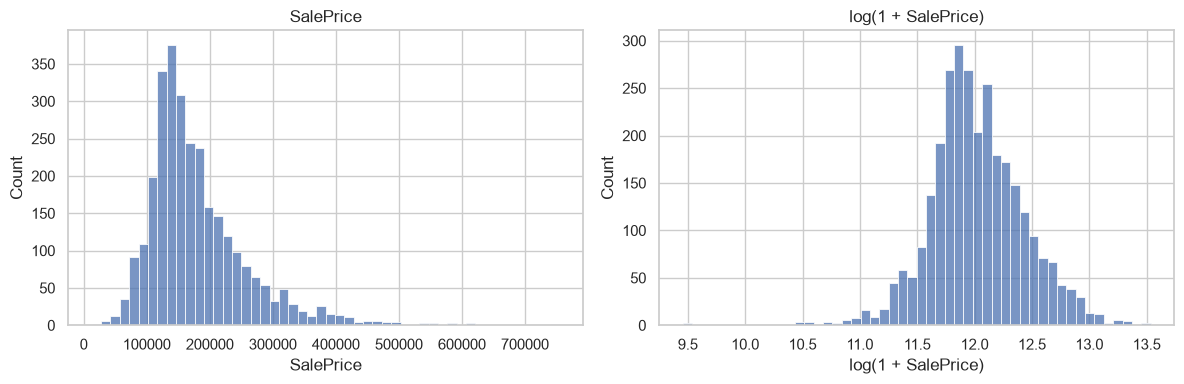

mean: 180801 | median: 160000
min: 12789 | max: 755000
skew raw: 1.74 | skew log: -0.01


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean_df["SalePrice"], bins=50, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(clean_df["SalePrice"]), bins=50, ax=axes[1])
axes[1].set_title("log(1 + SalePrice)")
axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print("mean:", round(clean_df["SalePrice"].mean()), "| median:", round(clean_df["SalePrice"].median()))
print("min:", clean_df["SalePrice"].min(), "| max:", clean_df["SalePrice"].max())
print("skew raw:", round(clean_df["SalePrice"].skew(), 2),
      "| skew log:", round(np.log1p(clean_df["SalePrice"]).skew(), 2))

**What the plot shows:** most houses sell between about 100k and 250k, with the peak around 140k–150k. The distribution is skewed to the right: a few expensive houses (up to about 750k) form a long tail, which pulls the mean ([mean]) above the median ([median]). After the log transform the shape is much more symmetric and bell-shaped (skew went from [raw skew] to [log skew]), so cheap and mid-range houses are easier to read. A few very cheap houses still show up as a small tail on the left.

### Summary

After cleaning, the data has 2927 rows and 85 columns. The only remaining NaN is `Garage Yr Blt` (159 rows: houses without a garage, plus a couple where the year is missing). We left it empty on purpose, since 0 would be a fake year.

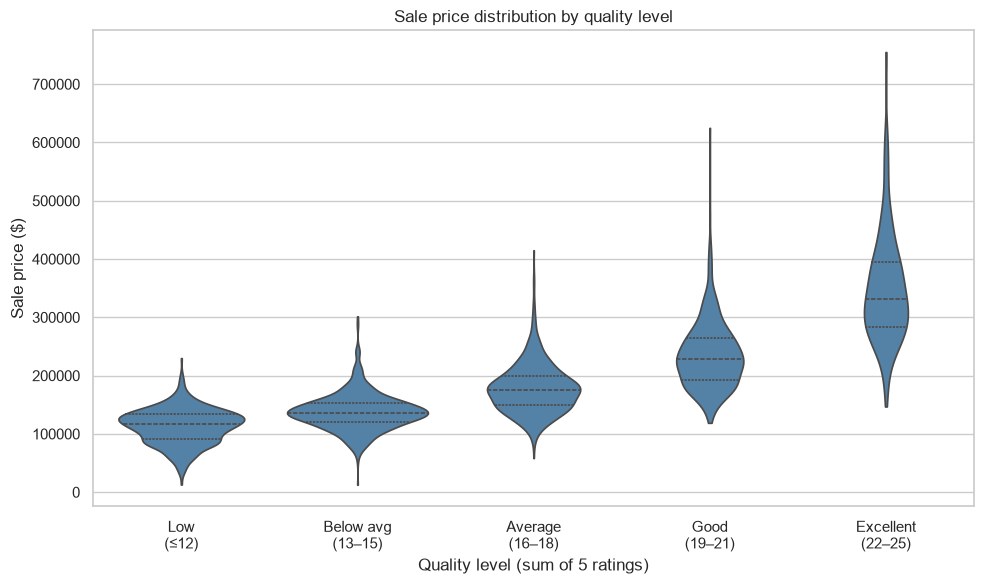

In [22]:
from preprocessing import add_quality_scores

heat_df = add_quality_scores(clean_df)
heat_df["Quality Score"] = heat_df.filter(like=" Num").sum(axis=1)

labels = ["Low\n(≤12)", "Below avg\n(13–15)", "Average\n(16–18)", "Good\n(19–21)", "Excellent\n(22–25)"]
heat_df["Quality Level"] = pd.cut(heat_df["Quality Score"], bins=[0, 12, 15, 18, 21, 25], labels=labels)

plt.figure(figsize=(10, 6))
sns.violinplot(data=heat_df, x="Quality Level", y="SalePrice", color="steelblue",
               inner="quartile", cut=0)
plt.grid(axis="x", visible=False)
plt.ylabel("Sale price ($)")
plt.xlabel("Quality level (sum of 5 ratings)")
plt.title("Sale price distribution by quality level")
plt.tight_layout()
plt.show()

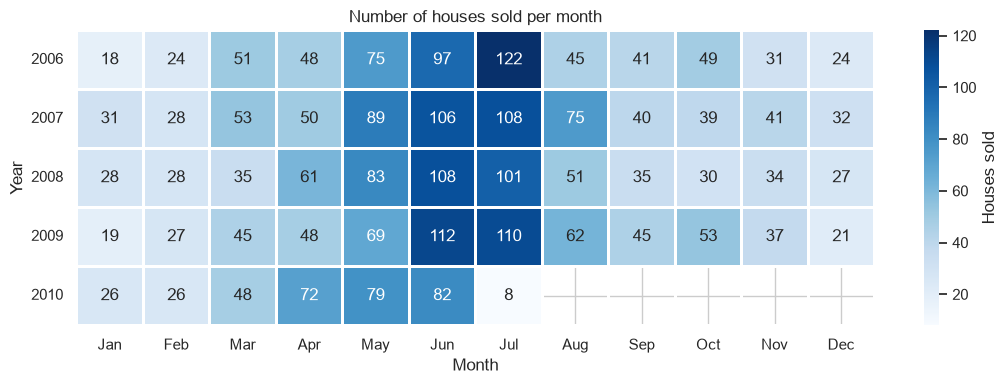

In [23]:
sales = clean_df.pivot_table(index="Yr Sold", columns="Mo Sold", values="SalePrice", aggfunc="count")
sales.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(11, 4))
sns.heatmap(sales, annot=True, fmt=".0f", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Houses sold"})
plt.xlabel("Month")
plt.ylabel("Year")
plt.title("Number of houses sold per month")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

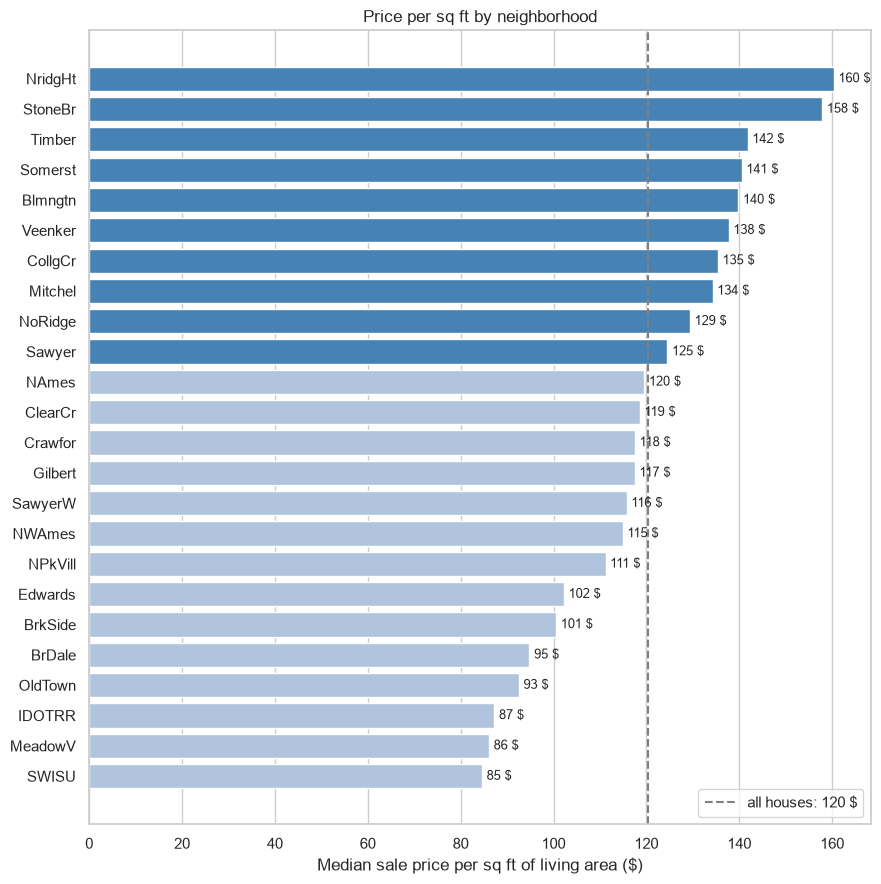

In [ ]:
df = clean_df.copy()
df["Price per SF"] = df["SalePrice"] / df["Gr Liv Area"]

nb = df.groupby("Neighborhood")["Price per SF"].agg(["count", "median"])
nb = nb[nb["count"] >= 20].sort_values("median") 
overall = df["Price per SF"].median()

plt.figure(figsize=(9, 9))
colors = ["steelblue" if v >= overall else "lightsteelblue" for v in nb["median"]]
plt.barh(nb.index, nb["median"], color=colors)
for i, v in enumerate(nb["median"]):
    plt.text(v + 1, i, f"{v:.0f} $", va="center", fontsize=9)
plt.axvline(overall, color="gray", linestyle="--", label=f"all houses: {overall:.0f} $")
plt.grid(axis="y", visible=False)
plt.xlabel("Median sale price per sq ft of living area ($)")
plt.title("Price per sq ft by neighborhood")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

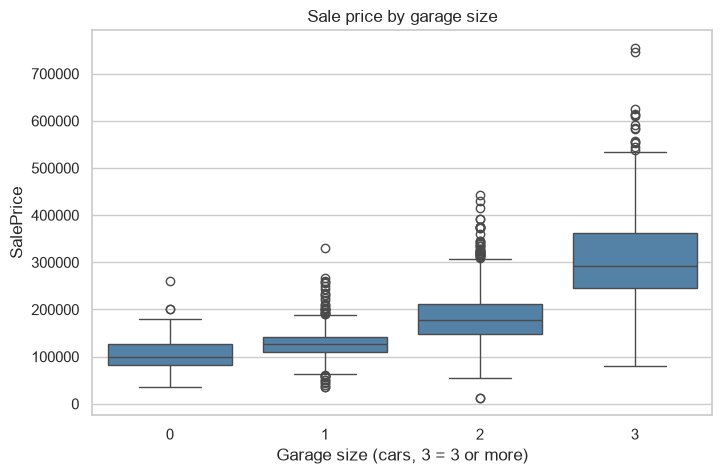

Garage Cars
0    100000.0
1    127000.0
2    177000.0
3    293077.0
Name: SalePrice, dtype: float64


In [25]:
garage = clean_df["Garage Cars"].clip(upper=3).astype(int)  

plt.figure(figsize=(8, 5))
sns.boxplot(x=garage, y=clean_df["SalePrice"], color="steelblue")
plt.xlabel("Garage size (cars, 3 = 3 or more)")
plt.ylabel("SalePrice")
plt.title("Sale price by garage size")
plt.show()

print(clean_df.groupby(garage)["SalePrice"].median())

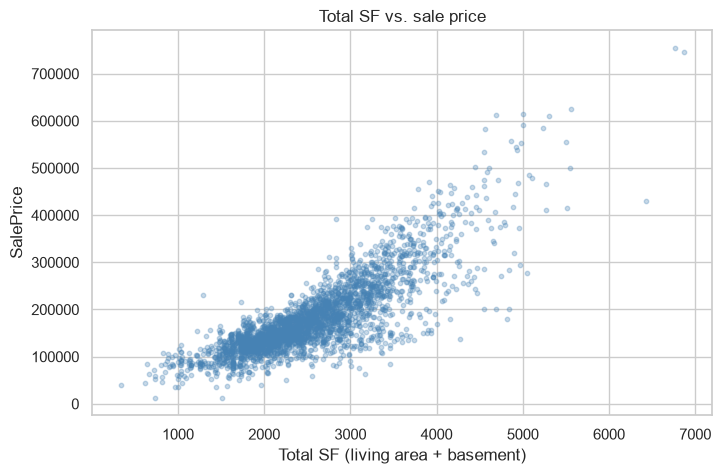

correlation: 0.83


In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["Total SF"], clean_df["SalePrice"], alpha=0.3, s=10, color="steelblue")
plt.xlabel("Total SF (living area + basement)")
plt.ylabel("SalePrice")
plt.title("Total SF vs. sale price")
plt.show()

print("correlation:", round(clean_df["Total SF"].corr(clean_df["SalePrice"]), 2))

Coefficient: 84.3
Intercept: -33445.02
Root mean squared error: 47459
R^2 on test data: 0.72


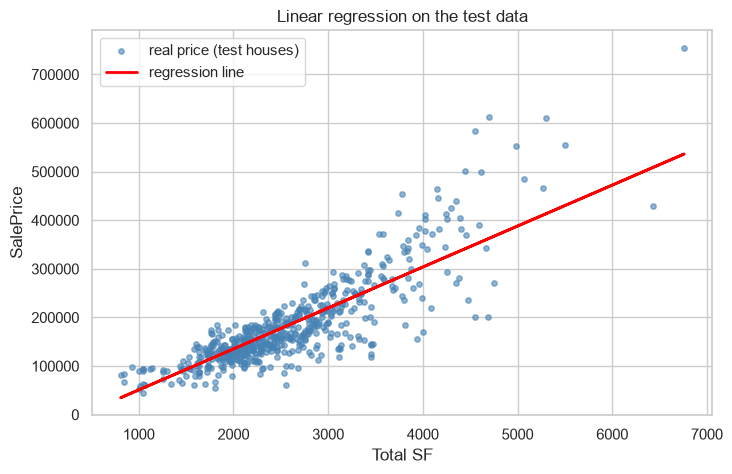

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = clean_df[["Total SF"]]
y = clean_df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Coefficient:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))
print("Root mean squared error:", round(mean_squared_error(y_test, y_pred) ** 0.5))
print("R^2 on test data:", round(r2_score(y_test, y_pred), 2))

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="steelblue", s=15, alpha=0.6, label="real price (test houses)")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="regression line")
plt.xlabel("Total SF")
plt.ylabel("SalePrice")
plt.title("Linear regression on the test data")
plt.legend()
plt.show()

In [28]:
compare = X_test.copy()
compare["real price"] = y_test
compare["predicted"] = y_pred.round()
compare["difference"] = compare["predicted"] - compare["real price"]
print(compare.head(5))

new_houses = pd.DataFrame({"Total SF": [1000, 2000, 3000, 4000]})
new_houses["predicted"] = model.predict(new_houses).round()
print(new_houses)

      Total SF  real price  predicted  difference
2393    3443.0      298236   256814.0    -41422.0
196     2288.0      132000   159443.0     27443.0
2310    2338.0      183500   163658.0    -19842.0
1732    2444.0      198444   172594.0    -25850.0
1100    3343.0      250000   248383.0     -1617.0
   Total SF  predicted
0      1000    50859.0
1      2000   135163.0
2      3000   219467.0
3      4000   303771.0
